# GoFast: анализ поведения пользователей и выручки

Учебный проект на данных за 2021 год. Данные не включены в репозиторий; см. README. Эта версия очищена от истории ревью. Изменены расчёт промокодов и проверка выручки на уровне пользователя; p-value и выводы необходимо обновить после полного запуска.

# Проект: Статистический анализ данных


Вы аналитик популярного сервиса аренды самокатов GoFast. Вам передали данные о некоторых пользователях из нескольких городов, а также об их поездках. Проанализируйте данные и проверьте некоторые гипотезы, которые могут помочь бизнесу вырасти.

- Чтобы совершать поездки по городу, пользователи сервиса GoFast пользуются мобильным приложением. Сервисом можно пользоваться:
- без подписки
    - абонентская плата отсутствует;
    - стоимость одной минуты поездки — 8 рублей;
    - стоимость старта (начала поездки) — 50 рублей;
- с подпиской Ultra
    - абонентская плата — 199 рублей в месяц;
    - стоимость одной минуты поездки — 6 рублей;
    - стоимость старта — бесплатно.


**Описание данных**

**Пользователи**
- user_id - уникальный идентификатор пользователя
- name - имя пользователя
- age - возраст
- city - город
- subscription_type	тип подписки (free, ultra)


**Поездки**
- user_id - уникальный идентификатор пользователя
- distance - расстояние, которое пользователь проехал в текущей сессии (в метрах)
- duration - продолжительность сессии (в минутах) — время с того момента, как пользователь нажал кнопку «Начать поездку» до момента, как он нажал кнопку «Завершить поездку»
- date	дата совершения поездки

**Подписки**
- subscription_type - тип подписки
- minute_price - стоимость одной минуты поездки по данной подписке
- start_ride_price - стоимость начала поездки
- subscription_fee - стоимость ежемесячного платежа

In [1]:
# импортируем библиотеки

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats as st
from scipy.stats import binom

#### Шаг 1. Загрузка данных

In [2]:
from pathlib import Path

DATA_FILES = {
    "users": [Path("data/users_go.csv")],
    "rides": [Path("data/rides_go.csv")],
    "subscriptions": [Path("data/subscriptions_go.csv")],
}
DATA_URLS = {
    "users": "https://code.s3.yandex.net/datasets/users_go.csv",
    "rides": "https://code.s3.yandex.net/datasets/rides_go.csv",
    "subscriptions": "https://code.s3.yandex.net/datasets/subscriptions_go.csv",
}

def load_dataset(key):
    for path in DATA_FILES[key]:
        if path.exists():
            return pd.read_csv(path)
    return pd.read_csv(DATA_URLS[key])

users_data = load_dataset("users")
rides_data = load_dataset("rides")
subscriptions_data = load_dataset("subscriptions")

##### Выведем первые строки датафреймов
и посмотрим на данные

In [3]:
users_data.head()

,user_id,name,age,city,subscription_type
0,1,Кира,22,Тюмень,ultra
1,2,Станислав,31,Омск,ultra
2,3,Алексей,20,Москва,ultra
3,4,Константин,26,Ростов-на-Дону,ultra
4,5,Адель,28,Омск,ultra


In [4]:
users_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            1565 non-null   int64 
 1   name               1565 non-null   object
 2   age                1565 non-null   int64 
 3   city               1565 non-null   object
 4   subscription_type  1565 non-null   object
dtypes: int64(2), object(3)
memory usage: 61.3+ KB


In [5]:
rides_data.head()

,user_id,distance,duration,date
0,1,4409.919140,25.599769,2021-01-01
1,1,2617.592153,15.816871,2021-01-18
2,1,754.159807,6.232113,2021-04-20
3,1,2694.783254,18.511000,2021-08-11
4,1,4028.687306,26.265803,2021-08-28


In [6]:
rides_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   18068 non-null  int64  
 1   distance  18068 non-null  float64
 2   duration  18068 non-null  float64
 3   date      18068 non-null  object 
dtypes: float64(2), int64(1), object(1)
memory usage: 564.8+ KB


In [7]:
subscriptions_data.head()

,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


In [8]:
subscriptions_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   subscription_type  2 non-null      object
 1   minute_price       2 non-null      int64 
 2   start_ride_price   2 non-null      int64 
 3   subscription_fee   2 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 196.0+ bytes


##### Выводы по шагу 1:
- В файле rides колонка с датой имеет тип object. Необходимо заменить на корректный тип;
- Также в rides в колонках distance и duration много знаков после запятой. Для удобства поправим в следующем шаге


#### Шаг 2. Предобработка данных

##### Основные шаги

In [9]:
# Приведем столбец date из датасета rides к типу даты pandas
rides_data['date'] = pd.to_datetime(rides_data['date'], format='%Y-%m-%d')

Введем столбец с номером года перед тем, как вводить столбец с номером месяца. Это позволит понять, есть ли в стоблце данные за период больше одного года

In [10]:
rides_data['year'] = pd.DatetimeIndex(rides_data['date']).year

rides_data['year'].value_counts()

year
2021    18068
Name: count, dtype: int64

In [11]:
# добавим столбец с номером месяца
rides_data['month'] = pd.DatetimeIndex(rides_data['date']).month

In [12]:
# проверим датафреймы на дубликаты

def count_duplicates(users_data, rides_data, subscriptions_data):
    # для пользователей
    duplicates_users_data = users_data.duplicated().sum()
    print(f'Количество дубликатов в users_data: {duplicates_users_data}')
    
    # для поездок
    duplicates_rides_data = rides_data.duplicated().sum()
    print(f'Количество дубликатов в rides_data: {duplicates_rides_data}')
    
    # для подписок
    duplicates_subscriptions_data = subscriptions_data.duplicated().sum()
    print(f'Количество дубликатов в subscriptions_data: {duplicates_subscriptions_data}')

count_duplicates(users_data, rides_data, subscriptions_data)

Количество дубликатов в users_data: 31
Количество дубликатов в rides_data: 0
Количество дубликатов в subscriptions_data: 0


In [13]:
# удалим явные дубликаты в users_data:
users_data = users_data.drop_duplicates(keep='first')

In [14]:
# проверим на наличие пропусков

display(users_data.isna().sum())
print('----------------')
display(rides_data.isna().sum())
print('----------------')
display(subscriptions_data.isna().sum())

user_id              0
name                 0
age                  0
city                 0
subscription_type    0
dtype: int64

----------------


user_id     0
distance    0
duration    0
date        0
year        0
month       0
dtype: int64

----------------


subscription_type    0
minute_price         0
start_ride_price     0
subscription_fee     0
dtype: int64

In [15]:
# округлим данные в столбцах distance и duration

rides_data['distance'] = rides_data['distance'].round(2)
rides_data['duration'] = rides_data['duration'].round(2)

##### Проверочные шаги

In [16]:
# проверяем повторно на наличие дубликатов
count_duplicates(users_data, rides_data, subscriptions_data)

Количество дубликатов в users_data: 0
Количество дубликатов в rides_data: 0
Количество дубликатов в subscriptions_data: 0


In [17]:
# выводим случайные строки, чтобы проверить, что изменения применились

display(users_data.sample(5))
print('----------------')
display(rides_data.sample(5))
print('----------------')
display(subscriptions_data.head())

,user_id,name,age,city,subscription_type
385,386,Ульяна,22,Тюмень,ultra
1414,1415,Илья,21,Краснодар,free
1055,1056,Милена,27,Пятигорск,free
694,695,Злата,14,Тюмень,ultra
109,110,Егор,23,Тюмень,ultra


----------------


,user_id,distance,duration,date,year,month
7111,741,1946.62,14.56,2021-12-20,2021,12
492,54,720.94,9.73,2021-09-05,2021,9
4431,477,2802.18,12.34,2021-05-06,2021,5
5298,569,688.66,5.65,2021-11-08,2021,11
1554,167,4547.60,25.05,2021-03-29,2021,3


----------------


,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


In [18]:
# убеждаемся, что тип даты в rides сменился 
rides_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   user_id   18068 non-null  int64         
 1   distance  18068 non-null  float64       
 2   duration  18068 non-null  float64       
 3   date      18068 non-null  datetime64[ns]
 4   year      18068 non-null  int32         
 5   month     18068 non-null  int32         
dtypes: datetime64[ns](1), float64(2), int32(2), int64(1)
memory usage: 705.9 KB


In [19]:
# проверяем, сколько строк осталось
users_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1534 entries, 0 to 1533
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            1534 non-null   int64 
 1   name               1534 non-null   object
 2   age                1534 non-null   int64 
 3   city               1534 non-null   object
 4   subscription_type  1534 non-null   object
dtypes: int64(2), object(3)
memory usage: 71.9+ KB


In [20]:
# округлим продолжительность поездки до целого числа и поменяем тип данных на int
rides_data['duration'] = np.ceil(rides_data['duration']).astype('int')

# проверяем
rides_data

,user_id,distance,duration,date,year,month
0,1,4409.92,26,2021-01-01,2021,1
1,1,2617.59,16,2021-01-18,2021,1
2,1,754.16,7,2021-04-20,2021,4
3,1,2694.78,19,2021-08-11,2021,8
4,1,4028.69,27,2021-08-28,2021,8
...,...,...,...,...,...,...
18063,1534,3781.10,20,2021-11-04,2021,11
18064,1534,2840.42,22,2021-11-16,2021,11
18065,1534,3826.19,19,2021-11-18,2021,11
18066,1534,2902.31,17,2021-11-27,2021,11


##### Выводы по шагу 2:
- дубликаты удалены - всего 31 строка
- ввели дополнительно столбец с указанием года: мы убедились, что данные в датафрейме только за один год - 2021
- столбец с датой приведен к корректному формату
- размерность выводимой информации в стоблцах distance и duration снижена
- продолжительность поездки округлили до минут, тип данных привели к int

#### Шаг 3. Исследовательский анализ данных

Выводы по всему шагу будут представлены в конце шага

##### Частота встречаемости городов

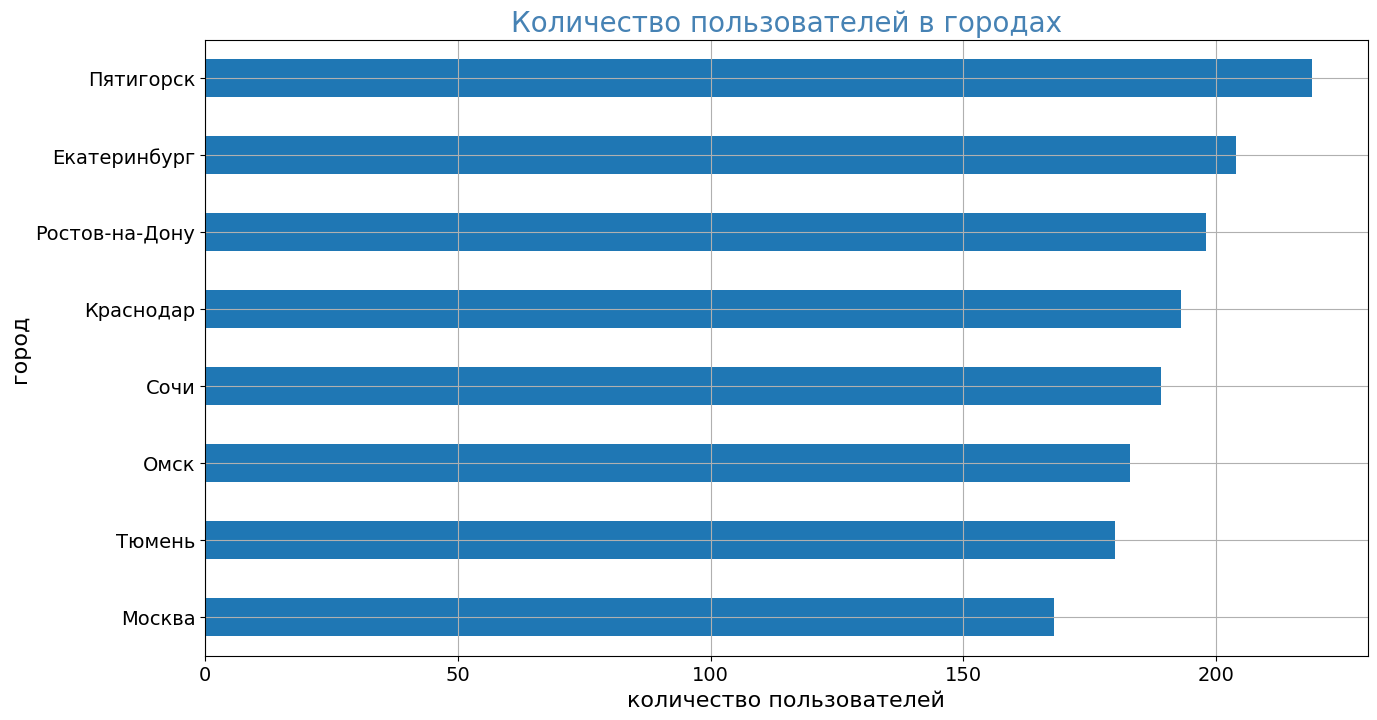

Таблица с разделением пользователей по городам:


,количество пользователей
city,
Пятигорск,219
Екатеринбург,204
Ростов-на-Дону,198
Краснодар,193
Сочи,189
Омск,183
Тюмень,180
Москва,168


In [21]:
# построим график

(
users_data
    .pivot_table(index='city', values='user_id', aggfunc='count')
    .sort_values(by='user_id', ascending=True)
    .plot(kind='barh', figsize=(15,8), legend=False, fontsize=14, grid=True)
);
plt.title('Количество пользователей в городах', fontsize=20, color='SteelBlue')
plt.xlabel('количество пользователей', fontsize=16)
plt.ylabel('город', fontsize=16);
plt.show()

# выведем таблицу
print('Таблица с разделением пользователей по городам:')
(
users_data
    .pivot_table(index='city', values='user_id', aggfunc='count')
    .sort_values(by='user_id', ascending=False)
    .rename(columns = {'user_id':'количество пользователей'})
) 

##### Соотношение пользователей с подпиской и без подписки

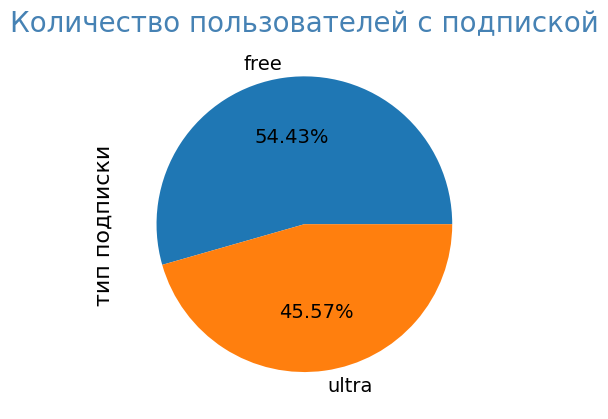

Разделение пользователей по типу подписки:


,количество пользователей
subscription_type,
free,835
ultra,699


In [22]:
# построим график

(
users_data['subscription_type']
    .value_counts()
    .plot(kind='pie', subplots=True, legend=False, fontsize=14, autopct='%.2f%%')
);
plt.title('Количество пользователей с подпиской', fontsize=20, color='SteelBlue')
plt.ylabel('тип подписки', fontsize=16)
plt.show()

# выведем таблицу
print('Разделение пользователей по типу подписки:')
(
users_data
    .pivot_table(index='subscription_type', values='user_id', aggfunc='count')
    .sort_values(by='user_id', ascending=False)
    .rename(columns = {'user_id':'количество пользователей'})
)

##### Возраст пользователей

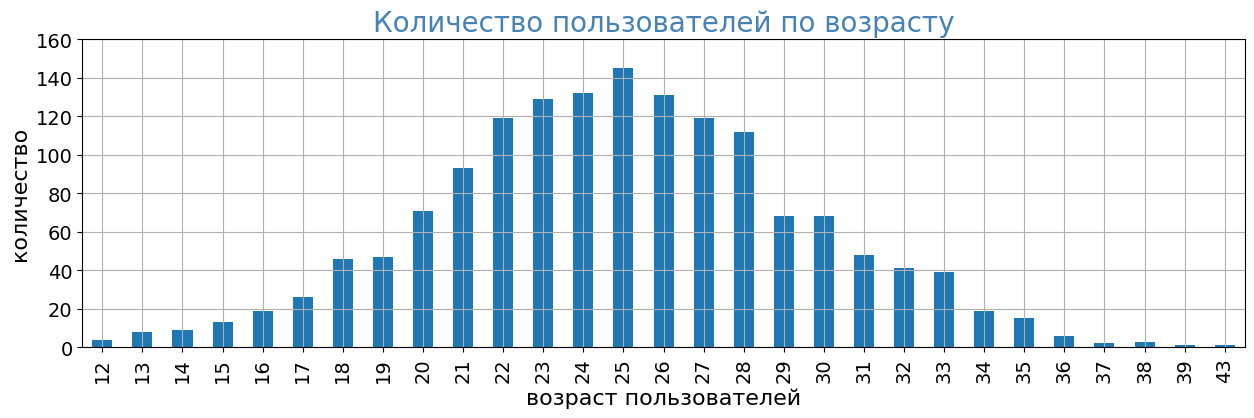

Разделение пользователей по возрасту - топ-10:


,количество пользователей
age,
25,145
24,132
26,131
23,129
22,119
27,119
28,112
21,93
20,71


In [23]:
# построим график

(
users_data
    .pivot_table(index='age', values='user_id', aggfunc='count')
    .plot(kind='bar', figsize=(15,4), legend=False, fontsize=14, grid=True, ylim=(0, 160))
);
plt.title('Количество пользователей по возрасту', fontsize=20, color='SteelBlue')
plt.xlabel('возраст пользователей', fontsize=16)
plt.ylabel('количество', fontsize=16);
plt.show()

# выведем таблицу,топ-10 значений
print('Разделение пользователей по возрасту - топ-10:')
(
users_data
    .pivot_table(index='age', values='user_id', aggfunc='count')
    .sort_values(by='user_id', ascending=False)
    .rename(columns = {'user_id':'количество пользователей'})
    .head(10)
)

##### Расстояние, которое пользователь преодолел за одну поездку

In [24]:
rides_data['distance'].describe()

count    18068.000000
mean      3070.659992
std       1116.831222
min          0.860000
25%       2543.227500
50%       3133.610000
75%       3776.220000
max       7211.010000
Name: distance, dtype: float64

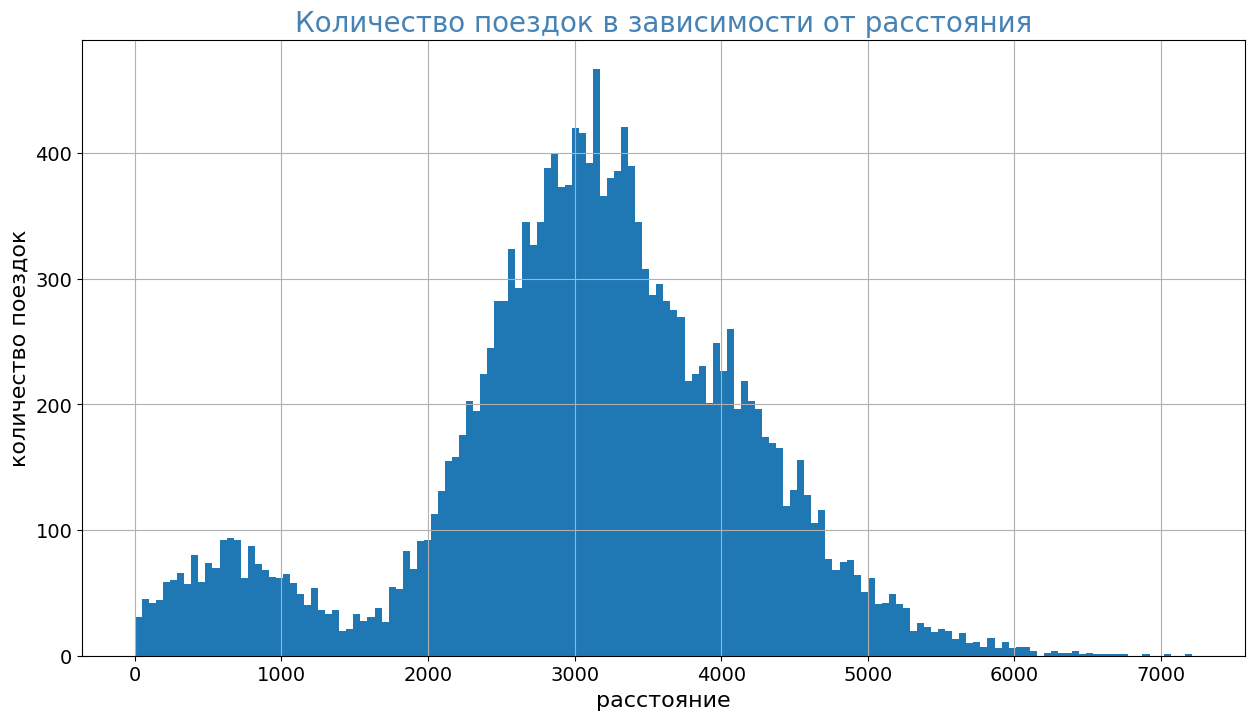

In [25]:
# построим график

(
rides_data['distance']
    .plot(kind = 'hist', figsize = (15,8), \
          legend = False, fontsize=14, bins=150, grid=True)
);
plt.title('Количество поездок в зависимости от расстояния', fontsize=20, color='SteelBlue')
plt.xlabel('расстояние', fontsize=16)
plt.ylabel('количество поездок', fontsize=16);
plt.show()

In [26]:
# дополнительно посмотрим, какие значения у нас имеются на разных процентилях: 1-ом, 25-ом, медиане, 75-ом и 99-ом

(
    rides_data[['distance']]
    .quantile([0.01, 0.25, 0.5, 0.75, 0.99]) # выбираем размах в 0,9976 квантилей
    .style.format("{:,.2f}")
)

,distance
0.010000,208.08
0.250000,"2,543.23"
0.500000,"3,133.61"
0.750000,"3,776.22"
0.990000,"5,478.62"


In [27]:
# выведем таблицу топ-10 значений по среднему пройденному расстоянию

(
rides_data
    .pivot_table(index='user_id', values='distance', aggfunc='mean').round(2)
    .sort_values(by='distance', ascending=False)
    .rename(columns = {'user_id':'количество пользователей'})
    .head(10)
)

,distance
user_id,
1309,4287.52
850,4004.84
644,3939.77
465,3917.56
381,3905.04
737,3902.97
1447,3899.60
1079,3885.84
246,3881.75


##### Продолжительность поездок

In [28]:
rides_data['duration'].describe()

count    18068.000000
mean        18.297653
std          6.093955
min          1.000000
25%         14.000000
50%         18.000000
75%         22.000000
max         41.000000
Name: duration, dtype: float64

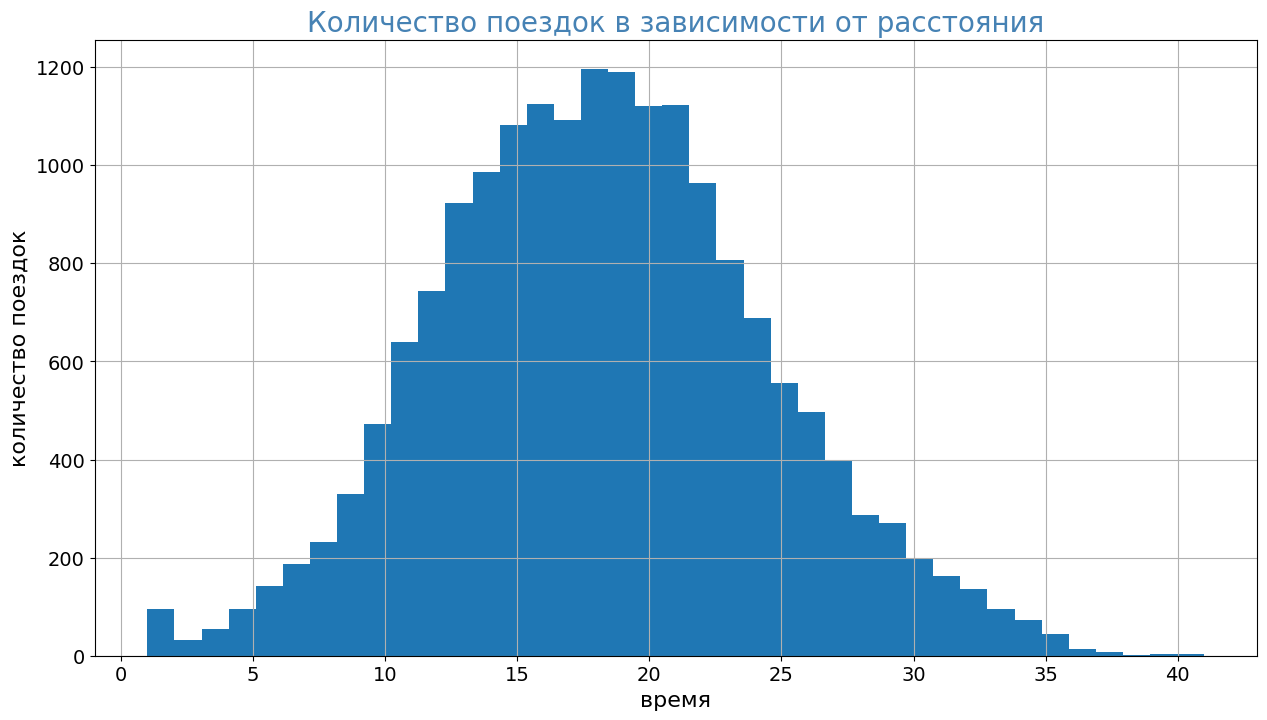

In [29]:
# построим график

(
rides_data['duration']
    .plot(kind = 'hist', figsize = (15,8), \
          legend = False, fontsize=14, bins=39, grid=True)
);
plt.title('Количество поездок в зависимости от расстояния', fontsize=20, color='SteelBlue')
plt.xlabel('время', fontsize=16)
plt.ylabel('количество поездок', fontsize=16);
plt.show()

In [30]:
# дополнительно посмотрим, какие значения у нас имеются на разных процентилях: 1-ом, 25-ом, медиане, 75-ом и 99-ом

(
    rides_data[['duration']]
    .quantile([0.01, 0.25, 0.5, 0.75, 0.99]) # выбираем размах в 0,9976 квантилей
    .style.format("{:,.2f}")
)

,duration
0.010000,4.00
0.250000,14.00
0.500000,18.00
0.750000,22.00
0.990000,33.00


In [31]:
# выведем таблицу топ-10 значений по среднему пройденному расстоянию

(
rides_data
    .pivot_table(index='user_id', values='duration', aggfunc='mean').round(2)
    .sort_values(by='duration', ascending=False)
    .rename(columns = {'user_id':'количество пользователей'})
    .head(10)
)

,duration
user_id,
657,26.60
643,26.25
126,26.00
354,26.00
522,25.83
183,25.60
494,25.00
239,24.80
20,24.60


##### Выводы по шагу 3:
- В лидерах по количеству прокатов самокатов Пятигорск. Примечательно, что в столице гораздо меньше людей пользуются услугами GoFast
- По большей части сервисом пользуются пользователи без подписки 54.43%
- Были замечены аномалии - около 100 поездок были продолжительностью меньше 1 минуты
- Возраст типового клиента в диапазоне от 22 до 29 лет
- В среднем за одну поездку пользователя проежают 3,07 км. Среднее время аренды самоката составляет 18 минут

#### Шаг 4. Объединение данных

##### Объединим 3 датафрейма в 1

In [32]:
# сначала объединим users и rides

us_and_rs = users_data.merge(rides_data, on='user_id', how='left')

# выведем на экран
us_and_rs.sample(5)

,user_id,name,age,city,subscription_type,distance,duration,date,year,month
10738,1009,Анатолий,21,Сочи,free,612.60,15,2021-12-16,2021,12
7609,780,Семен,13,Тюмень,free,3764.73,18,2021-10-10,2021,10
15838,1379,Регина,17,Ростов-на-Дону,free,2304.15,18,2021-08-23,2021,8
3392,365,Михаил,24,Ростов-на-Дону,ultra,2796.18,21,2021-09-02,2021,9
4440,478,Стефания,28,Ростов-на-Дону,ultra,2987.32,22,2021-09-20,2021,9


In [33]:
# объединим оставшиеся элементы
df = us_and_rs.merge(subscriptions_data, on='subscription_type', how='left')

# отсортируем по дате - в порядке возрастания 
df = df.sort_values(by='date', ascending=True)

# проверяем
df.head()

,user_id,name,age,city,subscription_type,distance,duration,date,year,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.92,26,2021-01-01,2021,1,6,0,199
13113,1184,Айдар,25,Пятигорск,free,5322.18,26,2021-01-01,2021,1,8,50,0
5445,582,Анна,26,Москва,ultra,2842.01,23,2021-01-01,2021,1,6,0,199
12775,1159,Ростислав,22,Тюмень,free,3098.41,19,2021-01-01,2021,1,8,50,0
17096,1467,Тимур,32,Екатеринбург,free,1875.82,17,2021-01-01,2021,1,8,50,0


In [34]:
# выведем информацию о новом датафрейма и проверим на наличие пропусков 

df.info()
print('----------------')
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 18068 entries, 0 to 11778
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            18068 non-null  int64         
 1   name               18068 non-null  object        
 2   age                18068 non-null  int64         
 3   city               18068 non-null  object        
 4   subscription_type  18068 non-null  object        
 5   distance           18068 non-null  float64       
 6   duration           18068 non-null  int64         
 7   date               18068 non-null  datetime64[ns]
 8   year               18068 non-null  int32         
 9   month              18068 non-null  int32         
 10  minute_price       18068 non-null  int64         
 11  start_ride_price   18068 non-null  int64         
 12  subscription_fee   18068 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int32(2), int64(6), object(3)
me

user_id              0
name                 0
age                  0
city                 0
subscription_type    0
distance             0
duration             0
date                 0
year                 0
month                0
minute_price         0
start_ride_price     0
subscription_fee     0
dtype: int64

##### Создадим из общего датафрейма 2:
1. c данными о пользователях без подписки;
2. с данными о пользователях с подпиской.

In [35]:
# без подписки
df_free = df.query('subscription_type == "free"')

# проверяем
df_free.sample(5)

,user_id,name,age,city,subscription_type,distance,duration,date,year,month,minute_price,start_ride_price,subscription_fee
10458,990,Елена,23,Сочи,free,2937.14,22,2021-01-01,2021,1,8,50,0
7736,789,Родион,23,Москва,free,3681.43,19,2021-02-09,2021,2,8,50,0
8469,846,Данил,28,Омск,free,4397.45,16,2021-10-27,2021,10,8,50,0
6777,718,Владислава,31,Москва,free,4413.41,32,2021-10-26,2021,10,8,50,0
8324,835,Эвелина,30,Москва,free,12.23,5,2021-09-19,2021,9,8,50,0


In [36]:
# с подпиской
df_ultra = df.query('subscription_type == "ultra"')

# проверяем
df_ultra.sample(5)

,user_id,name,age,city,subscription_type,distance,duration,date,year,month,minute_price,start_ride_price,subscription_fee
5794,617,Антон,31,Краснодар,ultra,4117.43,16,2021-03-17,2021,3,6,0,199
1189,127,Павел,25,Пятигорск,ultra,2666.83,27,2021-12-13,2021,12,6,0,199
2242,240,Артемий,25,Москва,ultra,3489.73,20,2021-04-22,2021,4,6,0,199
4673,504,Анна,35,Омск,ultra,2872.72,21,2021-01-09,2021,1,6,0,199
1437,156,Федор,20,Омск,ultra,2976.39,20,2021-04-10,2021,4,6,0,199


Построим графики и сравним данные о расстоянии и времени поездок для пользователей обеих категорий

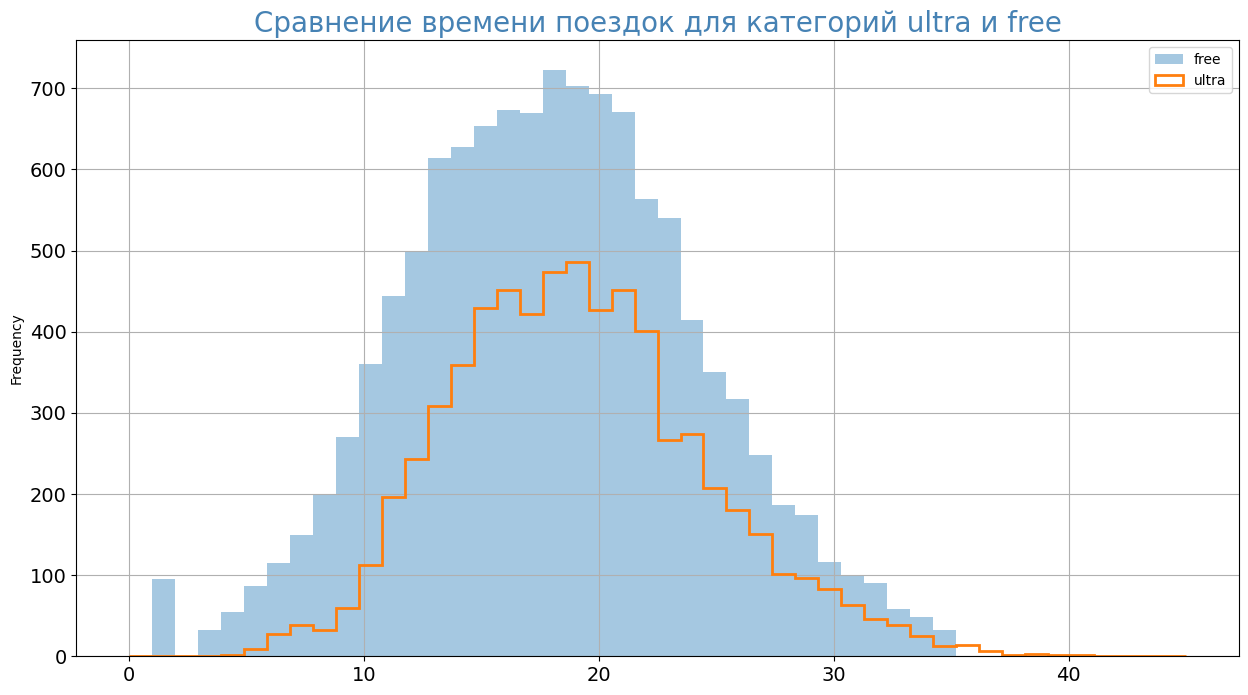

In [37]:
# продолжительность поездки

ax_duration = df_free['duration'].plot(
    kind = 'hist',
    figsize = (15,8),
    legend = True,
    fontsize=14,
    bins=46,
    grid=True,
    range=(0,45),
    label='free',
    alpha=0.4,
);

df_ultra['duration'].plot(
    kind = 'hist',
    figsize = (15,8),
    legend = True,
    fontsize=14,
    bins=46,
    grid=True,
    range=(0,45),
    label='ultra',
    alpha=1,
    ax=ax_duration,
    histtype='step',
    linewidth=2,
);

plt.title('Cравнение времени поездок для категорий ultra и free', fontsize=20, color='SteelBlue');

In [38]:
print(df_ultra['duration'].describe())
print('----------------')
print(df_free['duration'].describe())

count    6500.000000
mean       19.030000
std         5.576327
min         4.000000
25%        15.000000
50%        19.000000
75%        22.000000
max        41.000000
Name: duration, dtype: float64
----------------
count    11568.000000
mean        17.886151
std          6.329523
min          1.000000
25%         13.000000
50%         18.000000
75%         22.000000
max         35.000000
Name: duration, dtype: float64


In [39]:
# посмотрим на отличия в значениях у обеих категорий

df_ultra['duration'].describe() - df_free['duration'].describe()

count   -5068.000000
mean        1.143849
std        -0.753196
min         3.000000
25%         2.000000
50%         1.000000
75%         0.000000
max         6.000000
Name: duration, dtype: float64

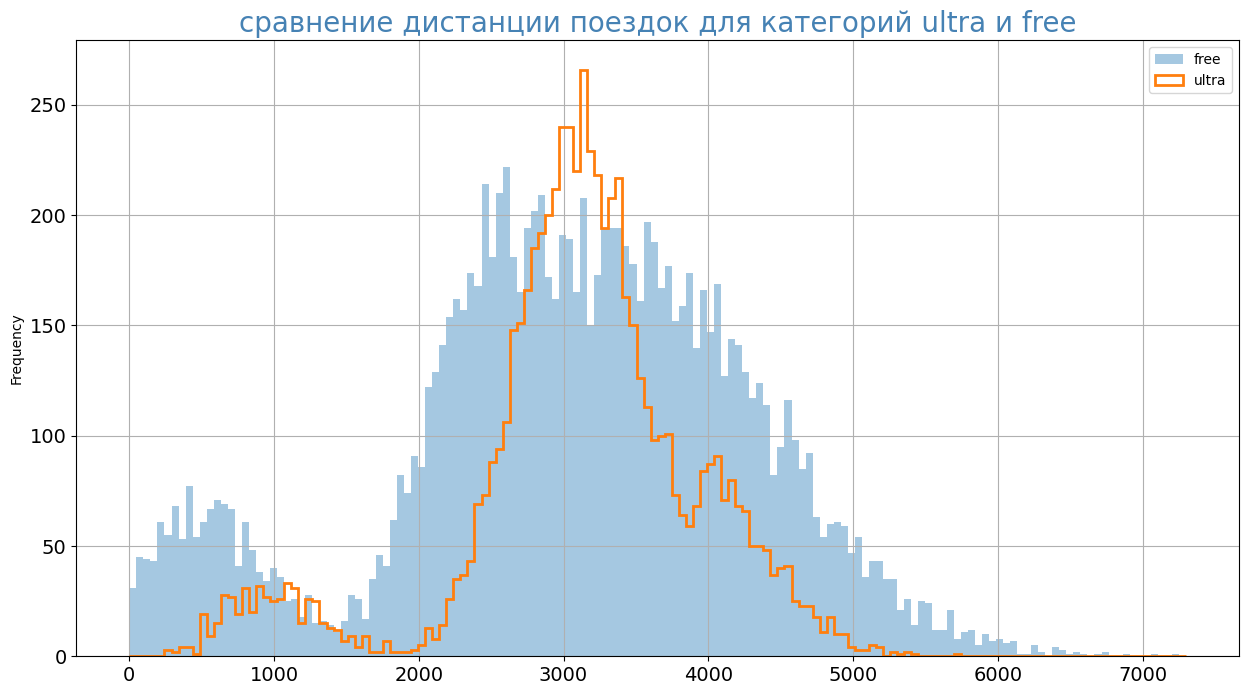

In [40]:
# расстояние

ax_distance = df_free['distance'].plot(
    kind = 'hist',
    figsize = (15,8),
    legend = True,
    fontsize=14,
    bins=150,
    grid=True,
    range=(0,7300),
    label='free',
    alpha=0.4,
);

df_ultra['distance'].plot(
    kind = 'hist',
    figsize = (15,8),
    legend = True,
    fontsize=14,
    bins=150,
    grid=True,
    range=(0,7300),
    label='ultra',
    alpha=1,
    ax=ax_distance,
    histtype='step',
    linewidth=2,
);

plt.title('сравнение дистанции поездок для категорий ultra и free', fontsize=20, color='SteelBlue');

In [41]:
print(df_ultra['distance'].describe())
print('----------------')
print(df_free['distance'].describe())

count    6500.000000
mean     3115.445431
std       836.895369
min       244.210000
25%      2785.447500
50%      3148.640000
75%      3560.577500
max      5699.770000
Name: distance, dtype: float64
----------------
count    11568.000000
mean      3045.495284
std       1246.173810
min          0.860000
25%       2366.560000
50%       3114.650000
75%       3905.695000
max       7211.010000
Name: distance, dtype: float64


In [42]:
# посмотрим на отличия в значениях у обеих категорий

df_ultra['distance'].describe() - df_free['distance'].describe()

count   -5068.000000
mean       69.950147
std      -409.278441
min       243.350000
25%       418.887500
50%        33.990000
75%      -345.117500
max     -1511.240000
Name: distance, dtype: float64

##### Выводы по шагу 4:
- Сделали общий датафрейм из трех отдельных;
- Из него отдельно выделили в отдельные датафреймы с данными о пользователях: с подпиской и без нее
- По продолжительно отличий в поведений у категорий ultra и free практически нет, однако по расстоянию в глаза бросается разница в разбросе (почти в 400 метров), а также среднее и медианное значения(пользователи ultra проезжают больше)

#### Шаг 5. Подсчёт выручки

##### Новый датафрейм
с агрегированными данными о поездках, в котором отобразим:
- суммарное расстояние,
- количество поездок,
- суммарное время для каждого пользователя за каждый месяц

In [43]:
# сделаем сводную таблицу
piv = (df.pivot_table(
    index=['user_id', 'month'],
    values=['distance', 'duration', 'start_ride_price', 'minute_price', 'subscription_fee'], 
    aggfunc={'distance':['sum', 'count'],
             'duration':'sum',
             'start_ride_price':'mean',
             'minute_price':'mean',
             'subscription_fee':'mean'})
       .reset_index()
      )

# добавим названия колонкам
piv.columns = [
    'user_id', # id пользователя
    'month', # месяц, в котором была совершена поездка 
    'count', # количество поездок
    'distance', # расстояние, которое проехал пользователь
    'duration', # продолжительность аренды
    'minute_price', # стоимость одной минуты поездки по данной подписке
    'start_ride_price', # стоимость начала поездки
    'subscription_fee' # стоимость подписки

]


# проверяем
piv.head(15)

,user_id,month,count,distance,duration,minute_price,start_ride_price,subscription_fee
0,1,1,2,7027.51,42,6.0,0.0,199.0
1,1,4,1,754.16,7,6.0,0.0,199.0
2,1,8,2,6723.47,46,6.0,0.0,199.0
3,1,10,2,5809.91,32,6.0,0.0,199.0
4,1,11,3,7003.50,56,6.0,0.0,199.0
5,1,12,2,6751.63,28,6.0,0.0,199.0
6,2,3,3,10187.73,63,6.0,0.0,199.0
7,2,4,2,6164.39,40,6.0,0.0,199.0
8,2,6,1,3255.34,14,6.0,0.0,199.0
9,2,7,2,6780.73,48,6.0,0.0,199.0


In [44]:
# проверка на пропуски
piv.isna().sum()

user_id             0
month               0
count               0
distance            0
duration            0
minute_price        0
start_ride_price    0
subscription_fee    0
dtype: int64

##### Новый столбец
Посчитаем помесячную выручку, которую принёс каждый пользователь.

Помесячная выручка считается по формуле:
- стоимость старта поездки * количество поездок + 
- стоимость одной минуты поездки * общая продолжительность всех поездок в минутах + 
- стоимость подписки

In [45]:
# новый столбец
piv['monthly_income'] = (
piv['start_ride_price'] * piv['count'] +
piv['minute_price'] * piv['duration'] +
piv['subscription_fee']
)

# выведем таблицу
piv.head(15)

,user_id,month,count,distance,duration,minute_price,start_ride_price,subscription_fee,monthly_income
0,1,1,2,7027.51,42,6.0,0.0,199.0,451.0
1,1,4,1,754.16,7,6.0,0.0,199.0,241.0
2,1,8,2,6723.47,46,6.0,0.0,199.0,475.0
3,1,10,2,5809.91,32,6.0,0.0,199.0,391.0
4,1,11,3,7003.50,56,6.0,0.0,199.0,535.0
5,1,12,2,6751.63,28,6.0,0.0,199.0,367.0
6,2,3,3,10187.73,63,6.0,0.0,199.0,577.0
7,2,4,2,6164.39,40,6.0,0.0,199.0,439.0
8,2,6,1,3255.34,14,6.0,0.0,199.0,283.0
9,2,7,2,6780.73,48,6.0,0.0,199.0,487.0


In [46]:
print('Выручка за 2021 (руб.):', int(piv['monthly_income'].sum()))

Выручка за 2021 (руб.): 3877893


##### Выводы по шагу 5:
- Создан новый датафрейм, в котором указаны суммарное расстояние, количество поездок и суммарное время для каждого пользователя за каждый месяц;
- В датафрейм добавлен столбец с помесячной выручкой, которую принёс каждый пользователь
- В 2021 году суммарная выручка составила 3,877,893 рубля

#### Шаг 6. Проверка гипотез

Продакт-менеджеры сервиса хотят увеличить количество пользователей с подпиской. Для этого они будут проводить различные акции, но сначала нужно выяснить несколько важных моментов.

##### О продолжительности

Важно понять, тратят ли пользователи с подпиской больше времени на поездки? Если да, то пользователи с подпиской могут быть «выгоднее» для компании. Проверьте гипотезу. Используйте исходные данные о продолжительности каждой сессии — отдельно для подписчиков и тех, у кого нет подписки.

**H0: пользователи с подпиской тратят столько же времени на поездки (или меньше), сколько и пользователи без подписки**

**H1: пользователи с подпиской тратят больше времени на поездки**

In [47]:
# уровень значимости
alpha = 0.01

# время первой группы пользователей (с подпиской)
ultra_time = df_ultra['duration']

# время второй группы пользователей (без подписки)
free_time = df_free['duration']

# проводим ttest_ind для двух выборок, в качестве альтернативной используем одностороннюю гипотезу «больше»
results61 = st.ttest_ind(ultra_time, free_time, alternative='greater')

print(f'p-value: {results61.pvalue}')

# проверяем p-value
if results61.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Нет оснований отвергнуть нулевую гипотезу')

p-value: 3.533140224216123e-34
Отвергаем нулевую гипотезу


**Интерпретация:** при тестировании отдельных поездок получено статистически значимое различие по длительности. Однако один пользователь может совершать несколько поездок: наблюдения не полностью независимы. Для строгого вывода на уровне пользователей требуется дополнительная проверка с агрегацией по пользователям или кластерным учётом повторных поездок.


##### О расстоянии

Расстояние одной поездки в 3130 метров — оптимальное с точки зрения износа самоката. Можно ли сказать, что среднее расстояние, которое проезжают пользователи с подпиской за одну поездку, не превышает 3130 метров? Проверьте гипотезу и сделайте выводы.

**H0: среднее расстояние, которое проезжают пользователи с подпиской за одну поездку, = 3130 метров**

**H1: среднеее расстояние больше 3130 метров**

In [48]:
# уровень значимости
alpha = 0.01

distance_data = df_ultra['distance']

# оптимальное занчение
optimal_value = 3130

# проводим ttest_1samp
results62 = st.ttest_1samp(distance_data, optimal_value, alternative='greater')

print('p-значение:', results62.pvalue)

# проверяем p-value
if results62.pvalue < alpha:
    print('Отвергаем нулевую гипотезу')
else:
    print('Не получилось отвергнуть нулевую гипотезу')

p-значение: 0.9195362605842414
Не получилось отвергнуть нулевую гипотезу


На выбранном уровне значимости нет достаточных оснований утверждать, что средняя длина поездки подписчиков превышает 3130 м. Это не доказывает, что средняя длина поездки не превышает 3130 м.

##### О выручке

Проверьте гипотезу о том, будет ли помесячная выручка от пользователей с подпиской по месяцам выше, чем выручка от пользователей без подписки. Сделайте вывод.

**H0: помесячная выручка от пользователей с подпиской по месяцам = выручке от пользователей без подписки**

**H1: помесячная выручка от пользователей с подпиской по месяцам выше, чем выручка от пользователей без подписки**

In [49]:
alpha = 0.01

# Для независимости наблюдений агрегируем месячную выручку на уровне пользователя.
# Так каждый пользователь представлен одной средней величиной, а не несколькими user-month строками.
user_month_revenue = piv.pivot_table(
    index="user_id", columns="subscription_fee", values="monthly_income", aggfunc="mean"
)

# Тип подписки постоянен для пользователя: fee=0 — free, fee>0 — ultra.
free_revenue = piv.loc[piv["subscription_fee"] == 0].groupby("user_id")["monthly_income"].mean()
ultra_revenue = piv.loc[piv["subscription_fee"] > 0].groupby("user_id")["monthly_income"].mean()

results63 = st.ttest_ind(ultra_revenue, free_revenue, equal_var=False, alternative="greater")
print(f"p-value: {results63.pvalue:.6g}")
if results63.pvalue < alpha:
    print("Отвергаем H0: средняя выручка на пользователя в месяц выше у подписчиков ultra.")
else:
    print("Не отвергаем H0: недостаточно данных для вывода о большей средней выручке на пользователя.")

p-value: 4.28463e-37
Отвергаем H0: средняя выручка на пользователя в месяц выше у подписчиков ultra.


**Интерпретация:** сравниваются средние месячные значения выручки на уровне пользователя (один пользователь — одно наблюдение). Это снижает проблему зависимости повторных наблюдений. Вывод относится к наблюдаемой ассоциации, а не доказывает причинный эффект подписки.


##### О количестве обращений

Представьте такую ситуацию: техническая команда сервиса обновила сервера, с которыми взаимодействует мобильное приложение. Она надеется, что из-за этого количество обращений в техподдержку значимо снизилось. Некоторый файл содержит для каждого пользователя данные о количестве обращений до обновления и после него. Какой тест вам понадобился бы для проверки этой гипотезы?

В данном случае мы бы применяли тест ttest_rel(), так как 2 выборки - парные, то есть зависимые. Проверяли бы гипотезу о равенстве среднего значения ГС до и после изменения.

- H0 в данном случае была бы такой: "количество обращений осталось без изменений"
- H1 была бы "обращений стало меньше". Аргумент для H1 - alternative='less'.


#### Шаг 7. Распределения

##### Про акцию с промокодами

Отделу маркетинга GoFast поставили задачу: нужно провести акцию с раздачей промокодов на один бесплатный месяц подписки, в рамках которой как минимум 100 существующих клиентов должны продлить эту подписку. То есть по завершении периода действия подписки пользователь может либо отказаться от неё, либо продлить, совершив соответствующий платёж. 

Эта акция уже проводилась ранее и по итогу выяснилось, что после бесплатного пробного периода подписку продлевают 10 % пользователей. Выясните, какое минимальное количество промокодов нужно разослать, чтобы вероятность не выполнить план была примерно 5 %. Подберите параметры распределения, описывающего эту ситуацию, постройте график распределения и сформулируйте ответ на вопрос о количестве промокодов.

- Исходя из данных, 100 клиентов == 10%. Значит, тест проводился на 1000 человек
- Биномиальное распределение, потому что клиенты с промокодом могут как продлить подписку, так и не продлевать ее, независимо друг от друга

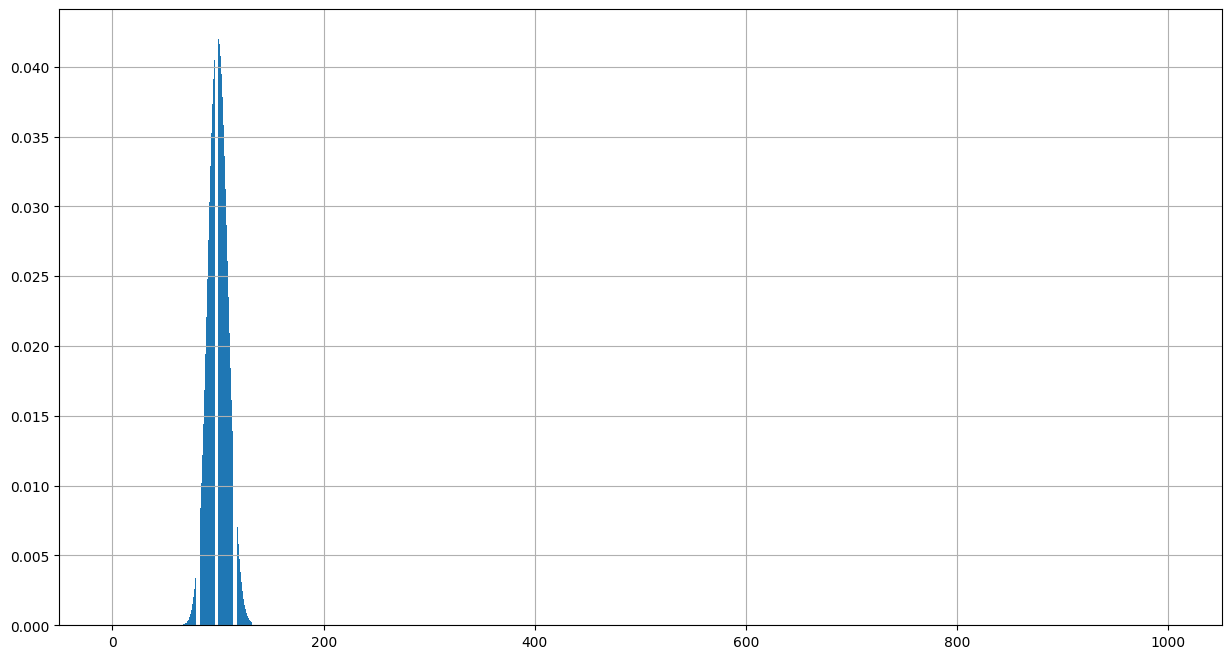

In [50]:
n = 1000 # количество попыток
p = 0.1 # вероятность успеха


distr = []

for k in range(0, n + 1):
    current_value = binom.pmf(k, n, p)
    distr.append(current_value)

plt.figure(figsize=(15, 8))
plt.bar(range(0, n + 1), distr)
plt.grid();

In [51]:
# Вероятность получить менее 100 продлений при 1000 отправленных промокодах.
# План считается выполненным при X >= 100, поэтому невыполнение — событие X < 100.
binom.cdf(99, 1000, 0.1)

np.float64(0.48458229043407863)

Необходимо найти такое количество промокодов, при котором 100+ человек не продлят подписку с вероятнотью до 5%

Если раздать 1161 промокодов, вероятность получить менее 100 продлений 0.0498


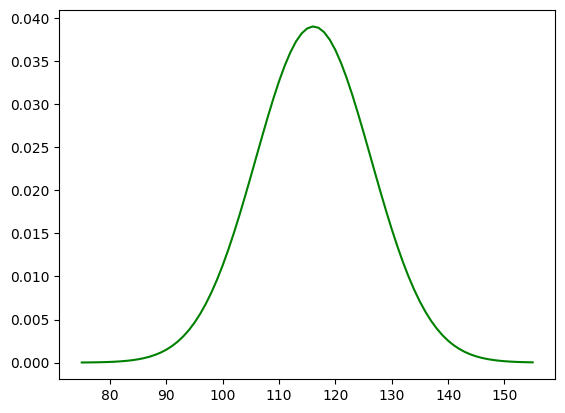

In [52]:
# для этого воспользуемся циклом while
# зададим параметры

n = 1000 # количество пользователей
p = 0.1 # вероятность
k = 100 # количество успешных попыток
plan_not_ok = 0.05 # порог, при котором останавливается цикл

while binom.cdf(k - 1, n, p) > plan_not_ok:
    n += 1
print(f'Если раздать {n} промокодов, вероятность получить менее 100 продлений', binom.cdf(k - 1, n, p).round(4))


mu = n * p
sigma = (n * p * (1 - p))**0.5

# границы интервала
left = int(mu - 4 * sigma)
right = int(mu + 4 * sigma)
x = list(range(left, right, 1))


plt.plot(x, st.norm.pdf(x, mu, sigma), 'g-');

Вывод:

Для того, чтобы как минимум 100 человек продлили подписку с вероятностью 5%, необходимо раздать 1172 промокода

##### Про push-уведомления
Отдел маркетинга рассылает клиентам push-уведомления в мобильном приложении. Клиенты могут открыть его или не открывать. Известно, что уведомления открывают около 40 % получивших клиентов. Отдел планирует разослать 1 млн уведомлений. С помощью аппроксимации постройте примерный график распределения и оцените вероятность того, что уведомление откроют не более 399,5 тыс. пользователей

0.15371708296369768


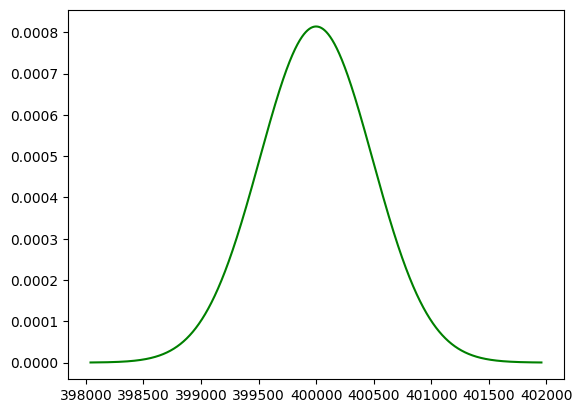

In [53]:
from math import sqrt

# задаём параметры биномиального распределения
n = 1000000
p = 0.4

# зададим мат.ожидание и ст.отклонение нормального распределения равными
# мат.ожиданию и ст.отклонению биномиального распределения
mu = n * p
sigma = sqrt(n * p * (1 - p))

# задаём нормальное распределение
distr = st.norm(mu, sigma)


# считаем вероятность хвоста слева от 399500 тысяч
result = distr.cdf(399500)
print(result)


# границы интервала
left = int(mu - 4 * sigma)
right = int(mu + 4 * sigma)
x = list(range(left, right, 1))


plt.plot(x, st.norm.pdf(x, mu, sigma), 'g-');

Вывод:


при условии, что будет разослано 1 млн push-уведомлений (которые открываются с вероятностью 40%), вероятность того, что уведомление откроют не более 399,5 тыс. пользователей равна 15.37%

## Итоговые выводы

- В выборке за 2021 год больше пользователей без подписки, чем с подпиской.
- При сравнении отдельных поездок получено статистически значимое различие в длительности; повторные поездки одного пользователя нарушают предположение независимости наблюдений. Для надёжного вывода на уровне пользователей требуется отдельная проверка.
- Для среднего расстояния поездки пользователей Ultra проверялась гипотеза о превышении 3130 м. p-value ≈ 0.920: данных недостаточно, чтобы утверждать, что среднее выше порога. Это не доказывает, что среднее не превышает 3130 м.
- После агрегации средней месячной выручки на уровне пользователя Welch t-test дал p-value ≈ 4.28 × 10⁻³⁷; в этой выборке средняя месячная выручка на пользователя выше у подписчиков Ultra. Это наблюдательный анализ, не доказательство причинности.
- Для промоакции успех — не менее 100 продлений. Вероятность невыполнения плана рассчитывается как `P(X < 100) = binom.cdf(99, n, 0.1)`. Минимальное число промокодов при вероятности невыполнения не выше 5% — **1161**.
- Общая расчётная выручка по таблице «пользователь–месяц» за 2021 год — **3 877 893 руб.**

### Ограничения

Это учебный анализ данных за 2021 год, а не оценка текущих показателей GoFast. Статистические выводы зависят от предположений тестов; для длительности поездок полезна дополнительная проверка методом, учитывающим кластеризацию поездок по пользователям.